# 🚨 Opération Redressement — notebook d'agence
**Module Predictive Analytics & Data Intelligence · M2 · Pairagogie du 13/11/2026**

Votre agence est missionnée par une marque **en déclin**. Ce notebook est **pré-codé** : vous exécutez les cellules (▶), vous lisez les résultats, et vous **prenez les décisions** dans les cellules marquées **✋ À VOUS**.

| Étape | Question | Livrable |
|---|---|---|
| 1 | Les données sont-elles fiables ? | rapport de nettoyage |
| 2 | D'où vient le déclin ? Structurel ou conjoncturel ? | diagnostic + prévision |
| 3 | Qui va partir ? (construire la cible) | taux de départ |
| 4 | Quels signaux annoncent le départ ? | 3 graphiques |
| 5 | Quelles variables a-t-on le droit d'utiliser ? | liste justifiée |
| 6 | Quel modèle est le plus fiable ? | tableau des 3 modèles |
| 7 | Quelle offre pour quel segment ? | next best offer |
| 8 | Qui cibler avec le budget ? | plan chiffré |

> ⚠️ Toutes les données sont **fictives**, créées pour l'exercice.

## 0 · Choisir sa marque et charger les fichiers

In [2]:
# ✋ À VOUS : écrivez le code de votre marque entre guillemets
#    "velin"  "atelier_nord"  "krousty"  "flixa"  "spark"
MARQUE = "atelier_nord"

In [4]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
COULEURS = ["#1f4e79", "#e07b39", "#3a9e6f", "#8064a2", "#c0504d"]

CONFIG = {
  # budget de la campagne (€), coût d'envoi par contact (€), valeur d'un client retenu (marge, €) — hypothèses du client
  "velin":        dict(nom="Maison Vélin", fenetre=180, date="date",    montant="montant_eur", budget=8000,   cout_contact=2.0, valeur=240),
  "atelier_nord": dict(nom="Atelier Nord", fenetre=120, date="date",    montant="montant_eur", budget=3500,   cout_contact=0.5, valeur=140),
  "krousty":      dict(nom="Krousty",      fenetre=60,  date="date",    montant="montant_eur", budget=1500,   cout_contact=0.3, valeur=70),
  "flixa":        dict(nom="Flixa",        fenetre=90,  date="date",    montant="montant_eur", budget=1200,   cout_contact=0.5, valeur=60),
  "spark":        dict(nom="Spark",        fenetre=60,  date="semaine", montant="achat_eur",   budget=800,    cout_contact=0.2, valeur=40),
}
C = CONFIG[MARQUE]
REF = pd.Timestamp("2026-03-31")      # date d'observation : on « se place » au 31 mars 2026
FIN_FENETRE = REF + pd.Timedelta(days=C["fenetre"])

# --- Chargement : sur Colab, une fenêtre s'ouvre pour déposer vos 5 fichiers CSV
DOSSIER = os.environ.get("DATA_DIR", ".")
try:
    from google.colab import files
    if not os.path.exists(f"{MARQUE}_clients.csv"):
        files.upload()
except ImportError:
    pass
lire = lambda f: pd.read_csv(os.path.join(DOSSIER, f"{MARQUE}_{f}.csv"))
clients, activite, digital = lire("clients"), lire("activite"), lire("digital")
campagne, mensuel = lire("campagne_test"), lire("mensuel")
for nom, t in [("clients", clients), ("activite", activite), ("digital", digital), ("campagne_test", campagne), ("mensuel", mensuel)]:
    print(f"{nom:<14} {t.shape[0]:>7} lignes × {t.shape[1]} colonnes")
print(f"\nMarque : {C['nom']} · fenêtre de départ : {C['fenetre']} jours après le {REF.date()}")

clients           5660 lignes × 10 colonnes
activite         41670 lignes × 7 colonnes
digital           5488 lignes × 7 colonnes
campagne_test     4000 lignes × 6 colonnes
mensuel             69 lignes × 7 colonnes

Marque : Atelier Nord · fenêtre de départ : 120 jours après le 2026-03-31


In [5]:
clients.head()

,client_id,date_inscription,age,ville,code_postal,genre,canal_acquisition,club_nord,grossesse_declaree,couleur_preferee
0,NRD-15495,2022-11-30,38,Paris,75019,H,site,non,non,rouge
1,NRD-10758,27/04/2024,18,Lille,59000,F,appli,non,non,rouge
2,NRD-13584,2022-08-26,53,Aubervilliers,93300,H,appli,oui,non,bleu
3,NRD-14237,2023-06-14,44,Marseille,13016,F,magasin,oui,non,bleu
4,NRD-14372,2019-04-16,18,Nantes,44000,F,site,non,non,vert


## 1 · Nettoyer : peut-on faire confiance aux données ?
Un data analyst passe souvent **plus de la moitié de son temps** à nettoyer. Exécutez, puis notez les chiffres dans votre note de cadrage.

In [6]:
avant = len(clients)
clients = clients.drop_duplicates()
doublons = avant - len(clients)
# dates dans deux formats (2023-05-12 et 12/05/2023)
iso = pd.to_datetime(clients["date_inscription"], format="%Y-%m-%d", errors="coerce")
fr  = pd.to_datetime(clients["date_inscription"], format="%d/%m/%Y", errors="coerce")
clients["date_inscription"] = iso.fillna(fr)
# âges impossibles
clients["age"] = pd.to_numeric(clients["age"], errors="coerce")
ages_faux = ((clients["age"] < 15) | (clients["age"] > 100)).sum()
clients.loc[(clients["age"] < 15) | (clients["age"] > 100), "age"] = np.nan
clients["age"] = clients["age"].fillna(clients["age"].median())
# villes mal saisies
villes_avant = clients["ville"].nunique()
clients["ville"] = clients["ville"].str.strip().str.title()
print(f"Doublons supprimés        : {doublons}")
print(f"Âges impossibles corrigés : {ages_faux} (remplacés par la médiane)")
print(f"Villes : {villes_avant} orthographes → {clients['ville'].nunique()} villes")
print(f"Clients sans fiche digitale : {len(set(clients.client_id) - set(digital.client_id))}")
print("\nValeurs manquantes restantes (%) :")
print((clients.isna().mean() * 100).round(1)[lambda s: s > 0])

Doublons supprimés        : 60
Âges impossibles corrigés : 12 (remplacés par la médiane)
Villes : 39 orthographes → 13 villes
Clients sans fiche digitale : 112

Valeurs manquantes restantes (%) :
genre                3.1
canal_acquisition    3.1
club_nord            3.0
dtype: float64


## 2 · Diagnostiquer : d'où vient le déclin ?
Le fichier mensuel retrace toute la clientèle de 2021 à 2026. **Une question = un graphique.**
- Quel segment décroche ? Depuis quand ?
- La baisse est-elle **structurelle** (tendance durable) ou **conjoncturelle** (accident ponctuel) ?

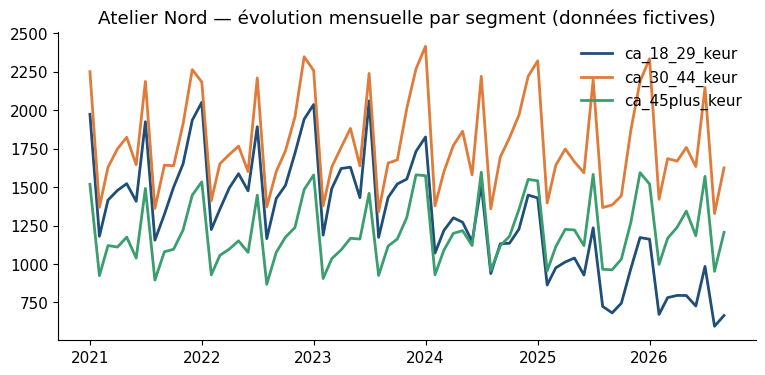

Total annuel par segment :
       ca_18_29_keur  ca_30_44_keur  ca_45plus_keur
annee                                              
2022         18840.0        21539.0         14128.0
2023         18861.0        21732.0         14485.0
2024         15225.0        21884.0         14886.0
2025         11776.0        20807.0         14579.0

Évolution (vide = segment lancé récemment) :
                2023 → 2025 (%)  2024 → 2025 (%)
ca_18_29_keur             -37.6            -22.7
ca_30_44_keur              -4.3             -4.9
ca_45plus_keur              0.7             -2.1


In [7]:
segs = [c for c in mensuel.columns if c != "mois" and not c.startswith(("ca_total", "ca_keur", "marge", "depenses", "nouveaux", "part_", "frequentation", "telechargements"))][:3]
mensuel["date"] = pd.to_datetime(mensuel["mois"])
fig, ax = plt.subplots()
for i, s in enumerate(segs):
    ax.plot(mensuel["date"], mensuel[s], label=s, color=COULEURS[i], lw=2)
ax.set_title(f"{C['nom']} — évolution mensuelle par segment (données fictives)")
ax.legend(frameon=False); plt.show()

mensuel["annee"] = mensuel["date"].dt.year
an = mensuel[mensuel.annee.between(2022, 2025)].groupby("annee")[segs].sum()
print("Total annuel par segment :")
print(an.round(0))
evo = pd.DataFrame({"2023 → 2025 (%)": (an.loc[2025] / an.loc[2023] - 1) * 100,
                    "2024 → 2025 (%)": (an.loc[2025] / an.loc[2024] - 1) * 100}).replace([np.inf, -np.inf], np.nan).round(1)
print("\nÉvolution (vide = segment lancé récemment) :")
print(evo)

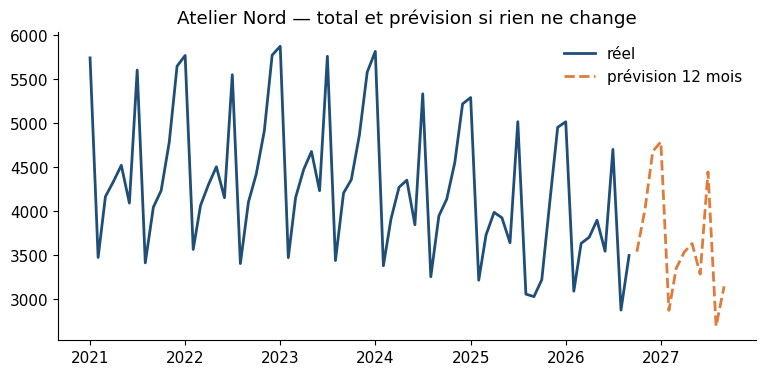

12 derniers mois : 46,231 · 12 prochains mois prévus : 43,970 → -4.9 %


In [8]:
# Prévision « si rien ne change » : tendance des 24 derniers mois, corrigée de la saisonnalité
from sklearn.linear_model import LinearRegression
total = mensuel[segs].sum(axis=1)
saison = total.groupby(mensuel["date"].dt.month).mean() / total.mean()
desais = total / mensuel["date"].dt.month.map(saison)
recent = mensuel.index[-24:]
lr = LinearRegression().fit(np.array(recent).reshape(-1, 1), desais[recent])
futur = np.arange(len(mensuel), len(mensuel) + 12)
mois_futurs = pd.date_range(mensuel["date"].iloc[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
prev = lr.predict(futur.reshape(-1, 1)) * mois_futurs.month.map(saison).values
fig, ax = plt.subplots()
ax.plot(mensuel["date"], total, color=COULEURS[0], lw=2, label="réel")
ax.plot(mois_futurs, prev, color=COULEURS[1], lw=2, ls="--", label="prévision 12 mois")
ax.set_title(f"{C['nom']} — total et prévision si rien ne change"); ax.legend(frameon=False); plt.show()
derniers12 = total.iloc[-12:].sum()
print(f"12 derniers mois : {derniers12:,.0f} · 12 prochains mois prévus : {prev.sum():,.0f} → {(prev.sum()/derniers12-1)*100:+.1f} %")

✋ **À VOUS (note de cadrage)** : en 3 phrases — quel segment fait chuter la marque, depuis quand, et le creux visible sur le graphique est-il structurel ou conjoncturel ?

## 3 · Construire la cible : qui est « parti » ?
Il n'y a **pas de colonne toute faite**. On se place au **31 mars 2026** :
- **Population** : les clients **actifs** (au moins une activité dans les 12 mois avant le 31/03/2026). Les autres sont déjà partis : on ne les prédit pas.
- **Cible Y = 1** : aucune activité dans la **fenêtre** qui suit (voir la durée de votre marque).

In [9]:
act = activite.copy()
act["d"] = pd.to_datetime(act[C["date"]])
if "statut_paiement" in act:                       # Flixa : seuls les paiements réussis comptent
    act_ok = act[act["statut_paiement"] == "ok"]
else:
    act_ok = act
avant12 = act_ok[(act_ok.d > REF - pd.Timedelta(days=365)) & (act_ok.d <= REF)]
dans_fenetre = act_ok[(act_ok.d > REF) & (act_ok.d <= FIN_FENETRE)]
actifs = avant12.client_id.unique()
base = pd.DataFrame({"client_id": actifs})
base["Y"] = (~base.client_id.isin(dans_fenetre.client_id)).astype(int)
print(f"Clients dans le fichier : {clients.client_id.nunique()} · actifs au 31/03/2026 : {len(base)}")
print(f"Taux de départ (Y = 1) dans les {C['fenetre']} jours : {base.Y.mean():.1%}")

Clients dans le fichier : 5600 · actifs au 31/03/2026 : 5000
Taux de départ (Y = 1) dans les 120 jours : 31.3%


### Variables de comportement — uniquement **avant** le 31/03/2026
Utiliser une donnée d'après le 31 mars, ce serait **lire la copie du voisin** : c'est une **fuite de données**.

In [10]:
h = act[(act.d <= REF) & (act.d > REF - pd.Timedelta(days=365))]
g = h.groupby("client_id")
feat = pd.DataFrame({
    "recence_jours": (REF - g.d.max()).dt.days,
    "frequence_12m": g.size(),
    "montant_12m": g[C["montant"]].sum(),
    "activite_3_derniers_mois": h[h.d > REF - pd.Timedelta(days=91)].groupby("client_id").size(),
})
feat["activite_3_derniers_mois"] = feat["activite_3_derniers_mois"].fillna(0)
feat["tendance"] = (feat["activite_3_derniers_mois"] / (feat["frequence_12m"] / 4)).round(2)   # 1 = stable, < 1 = ralentit
# variables numériques propres à votre marque (moyenne sur 12 mois)
for c in h.select_dtypes("number").columns:
    if c not in [C["montant"]]:
        feat[f"moy_{c}"] = g[c].mean()
if "statut_paiement" in h:
    feat["echecs_paiement_12m"] = h[h.statut_paiement == "echec"].groupby("client_id").size()
    feat["echecs_paiement_12m"] = feat["echecs_paiement_12m"].fillna(0)
if C["montant"] in h and (h[C["montant"]] < 0).any():
    feat["part_retours"] = h.assign(r=h[C["montant"]] < 0).groupby("client_id").r.mean()

data = (base.merge(feat.reset_index(), on="client_id", how="left")
            .merge(clients.drop_duplicates("client_id"), on="client_id", how="left")
            .merge(digital, on="client_id", how="left"))
data["anciennete_mois"] = ((REF - data["date_inscription"]).dt.days / 30.4).round(0)
data = data.drop(columns=["date_inscription"])
print(data.shape); data.head()

(5000, 24)


,client_id,Y,recence_jours,frequence_12m,montant_12m,activite_3_derniers_mois,tendance,moy_en_promo,part_retours,age,ville,code_postal,genre,canal_acquisition,club_nord,grossesse_declaree,couleur_preferee,visites_appli_90j,paniers_abandonnes_90j,avis_negatifs_12m,a_utilise_click_collect,note_satisfaction_10,bon_reactivation_juillet2026,anciennete_mois
0,NRD-12323,0,54,5,163.48,1.0,0.80,0.000000,0.200000,46.0,Marseille,13004,F,magasin,oui,non,bleu,8.0,2.0,0.0,non,10.0,non,13.0
1,NRD-14322,0,21,11,267.45,4.0,1.45,0.454545,0.272727,29.0,Paris,75010,F,instagram,non,oui,vert,7.0,3.0,0.0,non,5.1,non,26.0
2,NRD-11139,1,250,4,220.63,0.0,0.00,0.750000,0.000000,25.0,Lyon,69003,F,magasin,non,non,bleu,5.0,2.0,0.0,oui,7.1,envoye,12.0
3,NRD-15251,1,128,3,114.21,0.0,0.00,0.000000,0.333333,20.0,Lille,59000,H,magasin,non,non,noir,4.0,0.0,0.0,oui,6.5,envoye,88.0
4,NRD-10128,0,146,7,374.68,0.0,0.00,0.285714,0.142857,40.0,Paris,75002,H,site,non,non,beige,11.0,2.0,0.0,non,5.5,non,87.0


## 4 · Explorer : quels signaux annoncent le départ ?
Choisissez les **3 graphiques** qui racontent le mieux votre histoire. Titre = le message, pas la variable.

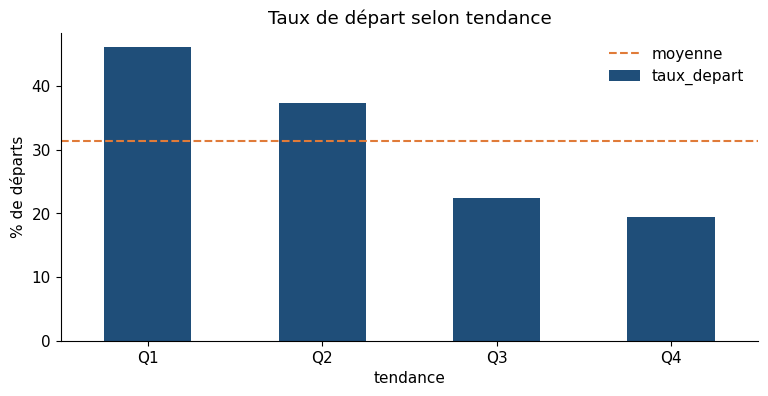

,taux_depart,nb
tendance,,
Q1,0.4608,1250
Q2,0.3728,1250
Q3,0.2248,1250
Q4,0.1936,1250


In [11]:
def taux_par(var, n_classes=4):
    s = data[var]
    if s.dtype.kind in "if" and s.nunique() > 8:
        s = pd.qcut(s.rank(method="first"), n_classes, labels=[f"Q{i+1}" for i in range(n_classes)])
    t = data.groupby(s.astype(str))["Y"].agg(["mean", "size"]).rename(columns={"mean": "taux_depart", "size": "nb"})
    return t

# ✋ À VOUS : changez la variable explorée (copiez un nom de colonne de data.head())
VARIABLE = "tendance"
t = taux_par(VARIABLE)
ax = (t["taux_depart"] * 100).plot.bar(color=COULEURS[0], rot=0)
ax.axhline(data.Y.mean() * 100, color=COULEURS[1], ls="--", label="moyenne")
ax.set_ylabel("% de départs"); ax.set_title(f"Taux de départ selon {VARIABLE}"); ax.legend(frameon=False); plt.show()
t

In [12]:
# Classement automatique : quelles variables séparent le plus les partants des fidèles ?
ecarts = {}
for v in data.columns.drop(["client_id", "Y"]):
    try:
        t = taux_par(v); t = t[t.nb >= 50]
        ecarts[v] = round((t.taux_depart.max() - t.taux_depart.min()) * 100, 1)
    except Exception:
        pass
pd.Series(ecarts, name="écart max (points)").sort_values(ascending=False).head(15)

,écart max (points)
bon_reactivation_juillet2026,95.9
visites_appli_90j,60.2
activite_3_derniers_mois,32.0
note_satisfaction_10,27.7
tendance,26.7
recence_jours,25.8
avis_negatifs_12m,21.6
age,19.2
frequence_12m,17.5
montant_12m,13.4


## 5 · Choisir les variables : a-t-on le **droit** de tout utiliser ?
Toutes les colonnes de vos fichiers n'ont pas leur place dans un modèle. Certaines posent un problème de **logique**, d'autres un problème **juridique ou éthique**, une autre n'a tout simplement **rien à faire là**. Combien sont-elles ? Lesquelles ? Pourquoi ? C'est à vous de le démontrer.

✋ **À VOUS** : écrivez les colonnes à écarter dans la liste ci-dessous, puis relancez les étapes 6 à 8. Comparez les résultats **avant / après** et justifiez chaque exclusion.

In [13]:
VARIABLES = [c for c in data.columns if c not in ["client_id", "Y"]]
# ✋ À VOUS : écrivez ici les variables à exclure, par ex. EXCLURE = ["nom_de_colonne", ...]
EXCLURE = []
VARIABLES = [v for v in VARIABLES if v not in EXCLURE]
print(len(VARIABLES), "variables utilisées :", VARIABLES)

22 variables utilisées : ['recence_jours', 'frequence_12m', 'montant_12m', 'activite_3_derniers_mois', 'tendance', 'moy_en_promo', 'part_retours', 'age', 'ville', 'code_postal', 'genre', 'canal_acquisition', 'club_nord', 'grossesse_declaree', 'couleur_preferee', 'visites_appli_90j', 'paniers_abandonnes_90j', 'avis_negatifs_12m', 'a_utilise_click_collect', 'note_satisfaction_10', 'bon_reactivation_juillet2026', 'anciennete_mois']


5-1. Modifier et exécuter la cellule des variables

In [14]:
VARIABLES = [c for c in data.columns if c not in ["client_id", "Y"]]
EXCLURE = ["bon_reactivation_juillet2026", "grossesse_declaree", "couleur_preferee", "code_postal"]
VARIABLES = [v for v in VARIABLES if v not in EXCLURE]
print(len(VARIABLES), "variables utilisées :", VARIABLES)

18 variables utilisées : ['recence_jours', 'frequence_12m', 'montant_12m', 'activite_3_derniers_mois', 'tendance', 'moy_en_promo', 'part_retours', 'age', 'ville', 'genre', 'canal_acquisition', 'club_nord', 'visites_appli_90j', 'paniers_abandonnes_90j', 'avis_negatifs_12m', 'a_utilise_click_collect', 'note_satisfaction_10', 'anciennete_mois']


6-

In [15]:
X = pd.get_dummies(data[VARIABLES], drop_first=True, dtype=float)
X = X.fillna(X.median())
y = data["Y"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

MODELES = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Arbre de décision":     DecisionTreeClassifier(max_depth=4, min_samples_leaf=40, random_state=42),
    "Forêt aléatoire":       RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
res, probas = [], {}
for nom, m in MODELES.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probas[nom] = p
    auc_cv = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc")
    res.append({"modèle": nom, "AUC train": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]),
                "AUC test": roc_auc_score(y_te, p), "AUC validation croisée": auc_cv.mean(), "écart-type CV": auc_cv.std()})
res = pd.DataFrame(res).set_index("modèle").round(3)
if (res["AUC test"] > 0.93).any():
    print("🚨 AUC > 0,93 : résultat suspect. Avant de vous réjouir, demandez-vous pourquoi. Retournez à l'étape 5.")
res

,AUC train,AUC test,AUC validation croisée,écart-type CV
modèle,,,,
Régression logistique,0.870,0.867,0.863,0.010
Arbre de décision,0.844,0.823,0.823,0.005
Forêt aléatoire,0.881,0.845,0.843,0.007


Sauvegarde du model

In [ ]:
res_apres = res.copy()

compare l’AUC de la régression logistique avec et sans genre, sur le même découpage

In [16]:
def auc_sans(exclusions):
    V = [v for v in data.columns if v not in ["client_id", "Y"] + exclusions]
    X = pd.get_dummies(data[V], drop_first=True, dtype=float); X = X.fillna(X.median())
    Xa, Xb, ya, yb = train_test_split(X, data["Y"], test_size=0.3, random_state=42, stratify=data["Y"])
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xa, ya)
    return roc_auc_score(yb, m.predict_proba(Xb)[:, 1])

base = ["bon_reactivation_juillet2026", "grossesse_declaree", "couleur_preferee", "code_postal"]
print("avec genre :", round(auc_sans(base), 3))
print("sans genre :", round(auc_sans(base + ["genre"]), 3))

avec genre : 0.867
sans genre : 0.867


Choisir le seuil

In [24]:
# ✋ À VOUS : choisissez le modèle retenu (simple, stable, explicable) et le seuil
MODELE_RETENU = "Régression logistique"
SEUIL = 0.5
p = probas[MODELE_RETENU]; pred = (p >= SEUIL).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f"Matrice de confusion (test, seuil {SEUIL}) :")
print(f"  partants bien repérés (VP) : {tp:>4}   partants ratés (FN)   : {fn:>4}")
print(f"  fausses alertes (FP)       : {fp:>4}   fidèles bien vus (VN) : {tn:>4}")
print(f"Exactitude {((tp+tn)/len(y_te)):.1%} · modèle naïf « personne ne part » {1-y_te.mean():.1%}")
print(f"Rappel {recall_score(y_te, pred):.1%} · Précision {precision_score(y_te, pred, zero_division=0):.1%}")

Matrice de confusion (test, seuil 0.5) :
  partants bien repérés (VP) :  273   partants ratés (FN)   :  196
  fausses alertes (FP)       :  100   fidèles bien vus (VN) :  931
Exactitude 80.3% · modèle naïf « personne ne part » 68.7%
Rappel 58.2% · Précision 73.2%


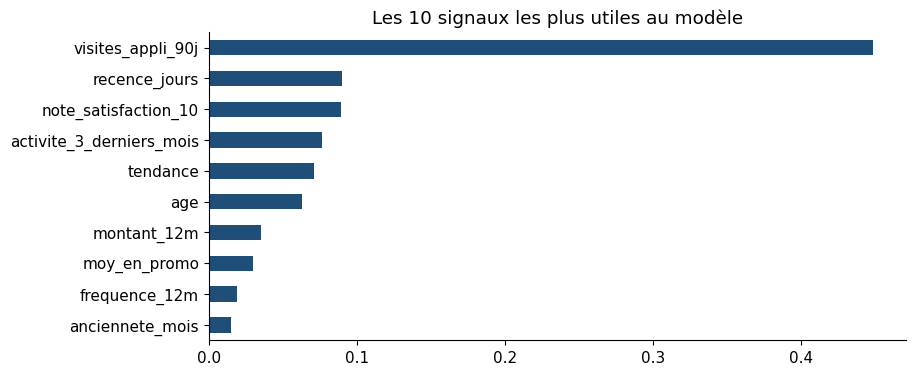

In [25]:
# Qu'est-ce qui pèse dans le modèle ? (forêt aléatoire)
imp = pd.Series(MODELES["Forêt aléatoire"].feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot.barh(color=COULEURS[0]); plt.title("Les 10 signaux les plus utiles au modèle"); plt.show()

## 7 · Quelle offre pour quel segment ? (campagne test)
Le client a testé 3 offres + un groupe **contrôle** (aucune offre). L'**effet réel** d'une offre = taux de réaction de l'offre **moins** taux du contrôle (*uplift*).

Taux de réaction (%) :
offre    controle  livraison_offerte  programme_reprise  remise_20
segment                                                           
18-29         9.8               15.9               19.3       16.2
30-44        14.3               20.5               17.4       17.8
45+          14.7               17.3               15.5       18.1

Uplift vs contrôle (points) :
offre    livraison_offerte  programme_reprise  remise_20
segment                                                 
18-29                  6.1                9.5        6.3
30-44                  6.1                3.0        3.4
45+                    2.6                0.7        3.3

Coût unitaire des offres (€) :
offre
livraison_offerte     5.0
programme_reprise     2.5
remise_20            13.0
Name: cout_offre_eur, dtype: float64

Gain net par contact (€) = uplift × 140 € − coût de l'offre :
offre    livraison_offerte  programme_reprise  remise_20
segment                                              

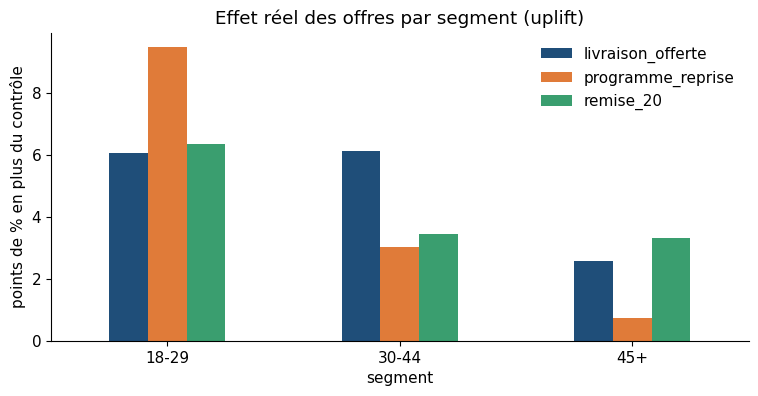

In [26]:
tx = campagne.pivot_table(index="segment", columns="offre", values="a_reagi_30j", aggfunc="mean")
uplift = tx.drop(columns="controle").sub(tx["controle"], axis=0)
cout_offre = campagne.groupby("offre").cout_offre_eur.mean()
# gain net par client contacté = clients retenus en plus × valeur d'un client retenu − coût de l'offre
gain_contact = uplift * C["valeur"] - cout_offre[uplift.columns]
print("Taux de réaction (%) :"); print((tx * 100).round(1))
print("\nUplift vs contrôle (points) :"); print((uplift * 100).round(1))
print("\nCoût unitaire des offres (€) :"); print(cout_offre.drop("controle").round(2))
print(f"\nGain net par contact (€) = uplift × {C['valeur']} € − coût de l'offre :"); print(gain_contact.round(2))
nbo = gain_contact.idxmax(axis=1)
print("\n➡ Next best offer par segment :"); print(nbo)
ax = (uplift * 100).plot.bar(rot=0, color=COULEURS[:3]); ax.set_ylabel("points de % en plus du contrôle")
ax.set_title("Effet réel des offres par segment (uplift)"); ax.legend(frameon=False); plt.show()

## 8 · Qui cibler avec le budget ?
On classe les clients du test du plus risqué au moins risqué, puis on extrapole à toute la base active.
Hypothèses du client : **budget**, **coût d'envoi par contact**, **valeur d'un client retenu**. On y ajoute le coût de l'**offre retenue** ; le taux de succès = son uplift moyen.

Offre retenue : programme_reprise · coût total par client ciblé : 3.00 €
Budget 3,500 € · coût/client ciblé 3.00 € · valeur client 140 € · taux de succès 4.4%
➡ Meilleur ciblage dans le budget : top 20 % — 1000 clients, 49.9 % des partants captés, profit net 1,814 €
   (sans contrainte de budget, l'optimum serait le top 30 % pour 4,500 € → profit 1,919 €)


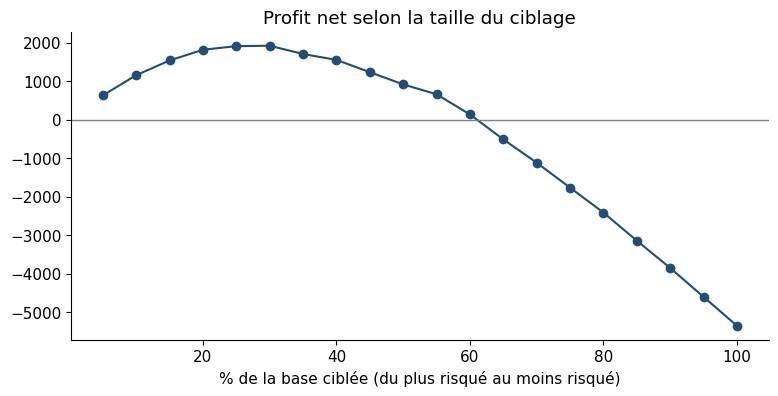

,% ciblé,clients ciblés,dont partants,% de partants captés,coût (€),clients sauvés,profit net (€),dans le budget
0,5,250,223,14.3,750,9.8,628,True
1,10,500,430,27.5,1500,19.0,1154,True
2,15,750,613,39.2,2250,27.0,1536,True
3,20,1000,780,49.9,3000,34.4,1814,True
4,25,1250,917,58.6,3750,40.4,1908,False
5,30,1500,1040,66.5,4500,45.9,1919,False
6,35,1750,1127,72.1,5250,49.7,1704,False
7,40,2000,1223,78.3,6000,53.9,1551,False
8,45,2250,1293,82.7,6750,57.0,1233,False
9,50,2500,1363,87.2,7500,60.1,915,False


In [27]:
# ✋ À VOUS : l'offre que vous recommandez (par défaut : celle qui rapporte le plus en moyenne)
OFFRE_RETENUE = gain_contact.mean().idxmax()
TAUX_SUCCES = float(uplift[OFFRE_RETENUE].mean())        # uplift moyen de l'offre, en proportion
BUDGET, VALEUR = C["budget"], C["valeur"]
COUT = C["cout_contact"] + float(cout_offre[OFFRE_RETENUE])
print(f"Offre retenue : {OFFRE_RETENUE} · coût total par client ciblé : {COUT:.2f} €")
facteur = len(data) / len(y_te)
ordre = np.argsort(-probas[MODELE_RETENU]); y_ord = y_te.values[ordre]
lignes = []
for pct in range(5, 101, 5):
    k = int(len(y_ord) * pct / 100)
    n_cibles = k * facteur; partants = y_ord[:k].sum() * facteur
    cout_total = n_cibles * COUT; sauves = partants * TAUX_SUCCES
    lignes.append({"% ciblé": pct, "clients ciblés": round(n_cibles), "dont partants": round(partants),
                   "% de partants captés": round(y_ord[:k].sum() / y_ord.sum() * 100, 1),
                   "coût (€)": round(cout_total), "clients sauvés": round(sauves, 1),
                   "profit net (€)": round(sauves * VALEUR - cout_total), "dans le budget": cout_total <= BUDGET})
plan = pd.DataFrame(lignes)
ok = plan[plan["dans le budget"]]
best = ok.loc[ok["profit net (€)"].idxmax()]
print(f"Budget {BUDGET:,} € · coût/client ciblé {COUT:.2f} € · valeur client {VALEUR} € · taux de succès {TAUX_SUCCES:.1%}")
print(f"➡ Meilleur ciblage dans le budget : top {best['% ciblé']} % — {best['clients ciblés']} clients, "
      f"{best['% de partants captés']} % des partants captés, profit net {best['profit net (€)']:,} €")
libre = plan.loc[plan["profit net (€)"].idxmax()]
print(f"   (sans contrainte de budget, l'optimum serait le top {libre['% ciblé']} % pour {libre['coût (€)']:,} € → profit {libre['profit net (€)']:,} €)")
fig, ax = plt.subplots()
ax.plot(plan["% ciblé"], plan["profit net (€)"], marker="o", color=COULEURS[0])
ax.axhline(0, color="grey", lw=1); ax.set_xlabel("% de la base ciblée (du plus risqué au moins risqué)")
ax.set_title("Profit net selon la taille du ciblage"); plt.show()
plan

Choisir le seuil

In [28]:
rows = []
for s in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    pred = (probas[MODELE_RETENU] >= s).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({"seuil": s, "VP": tp, "FN": fn, "FP": fp,
                 "rappel": round(recall_score(y_te, pred), 3),
                 "précision": round(precision_score(y_te, pred), 3),
                 "coût des erreurs (€)": round(fn * TAUX_SUCCES * VALEUR + fp * COUT)})
pd.DataFrame(rows).set_index("seuil")

,VP,FN,FP,rappel,précision,coût des erreurs (€)
seuil,,,,,,
0.20,407,62,340,0.868,0.545,1403
0.25,387,82,282,0.825,0.578,1352
0.30,365,104,224,0.778,0.620,1314
0.35,338,131,189,0.721,0.641,1376
0.40,318,151,150,0.678,0.679,1382
0.45,295,174,126,0.629,0.701,1452
0.50,273,196,100,0.582,0.732,1510


## 9 · Synthèse pour le deck
Copiez ces chiffres dans votre présentation, puis rédigez **3 insights** au format : **constat + chiffre + donc…**

In [29]:
print(f"MARQUE : {C['nom']}")
print(f"Base active : {len(data)} clients · départs à {C['fenetre']} j : {data.Y.mean():.1%}")
print(f"Variables utilisées : {len(VARIABLES)} · exclues : {EXCLURE}")
print(f"Modèle retenu : {MODELE_RETENU} · AUC test {res.loc[MODELE_RETENU, 'AUC test']} · AUC CV {res.loc[MODELE_RETENU, 'AUC validation croisée']}")
print(f"Next best offer : {nbo.to_dict()} · offre du plan : {OFFRE_RETENUE}")
print(f"Ciblage recommandé : top {best['% ciblé']} % · {best['clients ciblés']} clients · profit net estimé {best['profit net (€)']:,} €")

MARQUE : Atelier Nord
Base active : 5000 clients · départs à 120 j : 31.3%
Variables utilisées : 18 · exclues : ['bon_reactivation_juillet2026', 'grossesse_declaree', 'couleur_preferee', 'code_postal']
Modèle retenu : Régression logistique · AUC test 0.867 · AUC CV 0.863
Next best offer : {'18-29': 'programme_reprise', '30-44': 'livraison_offerte', '45+': 'livraison_offerte'} · offre du plan : programme_reprise
Ciblage recommandé : top 20 % · 1000 clients · profit net estimé 1,814 €


## 10 · Les défis experts
Le notebook vous a donné une première réponse. Les défis (voir votre cahier des charges) vous demandent d'aller **plus loin que les cellules pré-codées** : à vous d'écrire le code, seuls ou avec l'aide d'une IA, à condition de savoir l'expliquer.

In [30]:
# 🧰 Boîte à outils pour les défis — objets déjà calculés plus haut :
#   data            : base active (une ligne par client, Y = 1 si départ)
#   X_tr, X_te, y_tr, y_te : découpage train / test
#   probas[nom]     : probabilités de départ des clients du test, par modèle
#   MODELES, VARIABLES, res : modèles entraînés, variables utilisées, tableau des AUC
#   uplift, gain_contact, cout_offre, nbo : résultats de la campagne test
#   act, mensuel, campagne, clients, digital : les fichiers chargés
#   C : paramètres du client (budget, cout_contact, valeur, fenetre)
BINS = {"velin": ([0, 34, 54, 200], ["18-34", "35-54", "55+"]), "atelier_nord": ([0, 29, 44, 200], ["18-29", "30-44", "45+"]),
        "spark": ([0, 25, 35, 200], ["18-25", "26-35", "36+"])}
def segment_client(df):
    if MARQUE in BINS:
        return pd.cut(df["age"], BINS[MARQUE][0], labels=BINS[MARQUE][1]).astype(str)
    return df["canal_principal" if MARQUE == "krousty" else "formule"]
seg_te = segment_client(data.loc[X_te.index])     # segment de chaque client du test
print(seg_te.value_counts())

age
30-44    697
18-29    462
45+      341
Name: count, dtype: int64


In [32]:
# ✋ À VOUS : défi 1
facteur = len(data) / len(y_te)                       # 1 client du test en représente 3,33 de la base
p = pd.Series(probas[MODELE_RETENU], index=X_te.index)

def construire_plan(offres, uplifts):
    cout = C["cout_contact"] + offres.map(cout_offre)
    d = pd.DataFrame({"segment": seg_te, "offre": offres, "p": p, "uplift": uplifts, "cout": cout})
    d["profit_espere"] = d.p * d.uplift * VALEUR - d.cout
    d = d[d.profit_espere > 0].sort_values("profit_espere", ascending=False)
    return d[d.cout.cumsum() * facteur <= BUDGET]     # on remplit le budget dans l'ordre

def bilan(d):
    return {"clients ciblés": round(len(d) * facteur),
            "coût (€)": round(d.cout.sum() * facteur),
            "clients sauvés": round((d.p * d.uplift).sum() * facteur, 1),
            "profit net (€)": round(d.profit_espere.sum() * facteur)}

# Plan A : la même offre pour tout le monde (celle du notebook)
d_uni = construire_plan(pd.Series(OFFRE_RETENUE, index=seg_te.index),
                        pd.Series(TAUX_SUCCES, index=seg_te.index))

# Plan B : la meilleure offre de chaque segment
offres_seg = seg_te.map(nbo)
uplifts_seg = pd.Series([uplift.loc[s, o] for s, o in zip(seg_te, offres_seg)], index=seg_te.index)
d_seg = construire_plan(offres_seg, uplifts_seg)

print(pd.DataFrame({"offre unique": bilan(d_uni), "une offre par segment": bilan(d_seg)}))
print("\nRépartition du plan segmenté (clients de la base) :")
print((d_seg.groupby(["segment", "offre"]).size() * facteur).round())

                offre unique  une offre par segment
clients ciblés        1167.0                 1007.0
coût (€)              3500.0                 3487.0
clients sauvés          38.4                   59.8
profit net (€)        1879.0                 4886.0

Répartition du plan segmenté (clients de la base) :
segment  offre            
18-29    programme_reprise    820.0
30-44    livraison_offerte    187.0
dtype: float64


In [33]:
# ✋ À VOUS : défi 2
def fiabilite(groupes, nom):
    rows = []
    for g in sorted(groupes.dropna().unique()):
        idx = groupes[groupes == g].index
        yy, pp = y_te.loc[idx], p.loc[idx]
        if yy.nunique() < 2:
            continue
        pred = (pp >= SEUIL).astype(int)
        rows.append({nom: g, "clients test": len(idx), "taux de départ": round(yy.mean(), 3),
                     "AUC": round(roc_auc_score(yy, pp), 3),
                     "rappel": round(recall_score(yy, pred), 3),
                     "précision": round(precision_score(yy, pred, zero_division=0), 3)})
    return pd.DataFrame(rows).set_index(nom)

print(f"Seuil utilisé : {SEUIL}\n")
print(fiabilite(seg_te, "segment"))
print()
print(fiabilite(data.loc[X_te.index, "genre"].fillna("inconnu"), "genre"))

Seuil utilisé : 0.5

         clients test  taux de départ    AUC  rappel  précision
segment                                                        
18-29             462           0.437  0.864   0.678      0.801
30-44             697           0.257  0.874   0.559      0.667
45+               341           0.258  0.837   0.409      0.692

         clients test  taux de départ    AUC  rappel  précision
genre                                                          
Autre              34           0.265  0.813   0.667      0.500
F                 977           0.312  0.878   0.600      0.735
H                 439           0.321  0.846   0.539      0.752
inconnu            50           0.280  0.885   0.571      0.727


In [34]:
# ✋ À VOUS : défi 3 : résister aux hypothèses

def profit_fixe(d, valeur=VALEUR, coef_effet=1.0):
    # profit du plan tel quel (mêmes clients), si la valeur client ou l'effet de l'offre changent
    return ((d.p * d.uplift * coef_effet * valeur) - d.cout).sum() * facteur

# 1. Point mort : valeur client en dessous de laquelle le plan perd de l'argent
for nom, d in [("une offre par segment", d_seg), ("offre unique", d_uni)]:
    v_min = d.cout.sum() / (d.p * d.uplift).sum()
    print(f"{nom:<24} point mort : {v_min:.0f} € par client retenu (hypothèse du client : {VALEUR} €)")

# 2. Effet de l'offre deux fois plus faible
print()
for nom, d in [("une offre par segment", d_seg), ("offre unique", d_uni)]:
    print(f"{nom:<24} profit normal {profit_fixe(d):>6,.0f} € · effet ÷ 2 : {profit_fixe(d, coef_effet=0.5):>6,.0f} €")

# 3. Si on re-optimise le plan en sachant que l'effet est divisé par 2
print("\nPlan segmenté ré-optimisé, effet ÷ 2 :", bilan(construire_plan(offres_seg, uplifts_seg * 0.5)))

une offre par segment    point mort : 58 € par client retenu (hypothèse du client : 140 €)
offre unique             point mort : 91 € par client retenu (hypothèse du client : 140 €)

une offre par segment    profit normal  4,886 € · effet ÷ 2 :    699 €
offre unique             profit normal  1,879 € · effet ÷ 2 :   -811 €

Plan segmenté ré-optimisé, effet ÷ 2 : {'clients ciblés': 630, 'coût (€)': 1890, 'clients sauvés': np.float64(21.6), 'profit net (€)': 1140}


In [35]:
# ✋ À VOUS : défi 4 :  un modèle qui tient sur un seul pied ?
# 1. Quelle variable pèse le plus ?
coef = pd.Series(MODELES["Régression logistique"][-1].coef_[0], index=X.columns).abs().sort_values(ascending=False)
imp_rf = pd.Series(MODELES["Forêt aléatoire"].feature_importances_, index=X.columns).sort_values(ascending=False)
print("Régression logistique (coefficients standardisés, valeur absolue) :"); print(coef.head(5).round(2))
print("\nForêt aléatoire :"); print(imp_rf.head(5).round(3))

# 2. On la retire, on réentraîne, on mesure l'AUC
VAR_RETIREE = coef.index[0]   # si c'est une colonne dummy (ex. canal_acquisition_site), mettez le nom de la variable d'origine

def auc_logit(exclusions):
    V = [v for v in VARIABLES if v not in exclusions]
    Xn = pd.get_dummies(data[V], drop_first=True, dtype=float); Xn = Xn.fillna(Xn.median())
    Xa, Xb, ya, yb = train_test_split(Xn, data["Y"], test_size=0.3, random_state=42, stratify=data["Y"])
    mod = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    auc_test = roc_auc_score(yb, mod().fit(Xa, ya).predict_proba(Xb)[:, 1])
    auc_cv = cross_val_score(mod(), Xa, ya, cv=cv, scoring="roc_auc").mean()
    return round(auc_test, 3), round(auc_cv, 3)

print("\n(AUC test, AUC validation croisée)")
print("avec toutes les variables :", auc_logit([]))
print(f"sans {VAR_RETIREE} :", auc_logit([VAR_RETIREE]))


Régression logistique (coefficients standardisés, valeur absolue) :
visites_appli_90j           1.58
activite_3_derniers_mois    0.79
note_satisfaction_10        0.49
age                         0.31
frequence_12m               0.26
dtype: float64

Forêt aléatoire :
visites_appli_90j           0.449
recence_jours               0.090
note_satisfaction_10        0.089
activite_3_derniers_mois    0.076
tendance                    0.071
dtype: float64

(AUC test, AUC validation croisée)
avec toutes les variables : (np.float64(0.867), np.float64(0.863))
sans visites_appli_90j : (np.float64(0.751), np.float64(0.734))


Pour chiffrer l’impact sur la campagne/la part des partants captés dans le top 20 % avec et sans la variable

In [36]:
def captation(exclusions, pct=0.20):
    V = [v for v in VARIABLES if v not in exclusions]
    Xn = pd.get_dummies(data[V], drop_first=True, dtype=float); Xn = Xn.fillna(Xn.median())
    Xa, Xb, ya, yb = train_test_split(Xn, data["Y"], test_size=0.3, random_state=42, stratify=data["Y"])
    pp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xa, ya).predict_proba(Xb)[:, 1]
    k = int(len(yb) * pct)
    return round(yb.values[np.argsort(-pp)[:k]].sum() / yb.sum() * 100, 1)

print("Partants captés dans le top 20 % :", captation([]), "% avec · ", captation(["visites_appli_90j"]), "% sans")

Partants captés dans le top 20 % : 49.9 % avec ·  38.0 % sans


In [37]:
# ✋ À VOUS : défi 5 (propre à votre marque): prix ou déception ?
# Comportement d'achat sur les 12 mois avant le 31/03/2026
h = act[(act.d > REF - pd.Timedelta(days=365)) & (act.d <= REF)]
achats = h[h[C["montant"]] > 0]                       # achats seulement (les retours ont un montant négatif)
g = achats.groupby("client_id")
extra = pd.DataFrame({"part_achats_promo": g.en_promo.mean(), "panier_moyen": g[C["montant"]].mean()})
d5 = data.merge(extra, left_on="client_id", right_index=True, how="left")
d5["groupe"] = d5.Y.map({1: "partants", 0: "fidèles"})

print(d5.groupby("groupe")[["part_achats_promo", "part_retours", "panier_moyen",
                            "note_satisfaction_10", "avis_negatifs_12m"]].mean().round(3))

# Taux de départ selon la promo et selon la satisfaction (Q1 = valeurs les plus basses)
for var in ["part_achats_promo", "note_satisfaction_10"]:
    s = pd.qcut(d5[var].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
    print(f"\nTaux de départ selon {var}")
    print(d5.groupby(s)["Y"].agg(["mean", "size"]).round(3))

# Croisement : promo élevée × satisfaction basse
d5["promo_haute"] = d5.part_achats_promo > d5.part_achats_promo.median()
d5["satisf_basse"] = d5.note_satisfaction_10 < d5.note_satisfaction_10.median()
print("\nTaux de départ (lignes : promo haute ; colonnes : satisfaction basse)")
print(d5.pivot_table(index="promo_haute", columns="satisf_basse", values="Y", aggfunc="mean").round(3))

          part_achats_promo  part_retours  panier_moyen  note_satisfaction_10  \
groupe                                                                          
fidèles               0.415         0.192        58.788                 7.092   
partants              0.491         0.206        57.620                 6.349   

          avis_negatifs_12m  
groupe                       
fidèles               0.267  
partants              0.403  

Taux de départ selon part_achats_promo
                    mean  size
part_achats_promo             
Q1                 0.292  1210
Q2                 0.250  1210
Q3                 0.301  1209
Q4                 0.396  1210

Taux de départ selon note_satisfaction_10
                       mean  size
note_satisfaction_10             
Q1                    0.457  1226
Q2                    0.344  1226
Q3                    0.273  1226
Q4                    0.179  1226

Taux de départ (lignes : promo haute ; colonnes : satisfaction basse)
satisf_bass